# S-Phot stellar classifier — training and prediction

This notebook walks through:

1. **Training** an XGBoost multi-label model using hyperparameters from `tuning_results_5foldcv_2000_iter_ms_augmented/`
2. **Scoring** new stars from a PySSED `.dat` file (mock example in `data/mock_predict.dat`)

Run the notebook with the project virtual environment (Python 3.9):

```powershell
.\.venv\Scripts\Activate.ps1
python -m ipykernel install --user --name s-phot-classifier
jupyter notebook notebooks/stellar_classifier_workflow.ipynb
```

Select kernel **s-phot-classifier** in Jupyter.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import infer

TRAIN_DATA = REPO / "data" / "df_plus_ms.dat"
TRAIN_LABELS = REPO / "data" / "classes_plus_ms.dat"
TUNING_DIR = REPO / "tuning_results_5foldcv_2000_iter_ms_augmented"
ARTIFACTS = REPO / "artifacts"
MOCK_DATA = REPO / "data" / "mock_predict.dat"
MOCK_LABELS = REPO / "data" / "mock_predict_labels.txt"
PACKAGE = "Full"

print("Repo:", REPO)
print("Training table exists:", TRAIN_DATA.exists())
print("Artifacts exist:", (ARTIFACTS / "model.pkl").exists())

Repo: D:\Profils\ncox\Downloads\s-phot_stellar_classifier
Training table exists: True
Artifacts exist: True


## 1. Train (or reuse saved artifacts)

Tuning files contain **hyperparameters and class weights**, not fitted trees. Training fits XGBoost once and saves pickles under `artifacts/`.

Set `RUN_TRAINING = True` to refit (~5 minutes on the full ms-augmented table). Leave `False` if you already ran `python infer.py train --package Full`.

In [2]:
RUN_TRAINING = False

if RUN_TRAINING:
    import argparse

    args = argparse.Namespace(
        package=PACKAGE,
        data=str(TRAIN_DATA),
        labels=str(TRAIN_LABELS),
        tuning_dir=str(TUNING_DIR),
        artifacts=str(ARTIFACTS),
        holdout=False,
    )
    infer.cmd_train(args)
else:
    infer.load_artifacts(ARTIFACTS)
    print("Using existing artifacts in", ARTIFACTS)

Using existing artifacts in D:\Profils\ncox\Downloads\s-phot_stellar_classifier\artifacts


In [3]:
model, mlb, feature_columns, meta = infer.load_artifacts(ARTIFACTS)
print("Package:", meta["package"])
print("Features:", meta["n_features"])
print("Classes:", meta["classes"])

Package: Full
Features: 96
Classes: ['**', 'em*', 'ev*', 'lm*', 'ma*', 'ms*', 'pe*', 'v*', 'y*o']


## 2. Mock prediction dataset

`data/mock_predict.dat` contains three stars copied from the training table with renamed IDs (`MOCK_STAR_001` …). Same 9-line PySSED header and column layout as training.

Regenerate anytime:

```powershell
python scripts/create_mock_predict_data.py
```

In [4]:
if not MOCK_DATA.exists():
    raise FileNotFoundError(
        "Run: python scripts/create_mock_predict_data.py"
    )

mock_df, mock_classes = infer.preprocess(MOCK_DATA, labels_path=None)
print("Mock stars:", list(mock_df.index))
mock_classes.head()

D:\Profils\ncox\Downloads\s-phot_stellar_classifier\explore_commons.py:100: PerformanceWarning: indexing past lexsort depth may impact performance.
  pyssed_failed = np.array([i[0] for i in data[('Fitted', 'Teff', 'Value')].eq(0).values]
D:\Profils\ncox\Downloads\s-phot_stellar_classifier\explore_commons.py:101: PerformanceWarning: indexing past lexsort depth may impact performance.
  and [i[0] for i in data[('Fitted', 'Lum', 'Value')].eq(0).values])
D:\Profils\ncox\Downloads\s-phot_stellar_classifier\explore_commons.py:151: PerformanceWarning: indexing past lexsort depth may impact performance.
  coords = SkyCoord(data[("Adopted", "RA", "Value")].values * u.degree, data[("Adopted", "Dec", "Value")].values * u.degree)
D:\Profils\ncox\Downloads\s-phot_stellar_classifier\explore_commons.py:154: PerformanceWarning: indexing past lexsort depth may impact performance.
  data[("Adopted", "RA", "Value")] = coord1
D:\Profils\ncox\Downloads\s-phot_stellar_classifier\explore_commons.py:155: Perf

Mock stars: ['MOCK_STAR_001', 'MOCK_STAR_002', 'MOCK_STAR_003']


,class
MOCK_STAR_001,Unknown
MOCK_STAR_002,Unknown
MOCK_STAR_003,Unknown


## 3. Predict on mock input

Preprocessing matches `main.py` / `infer.py`: merge duplicate wavelengths, galactic coordinates, spectral transform, align to training columns.

In [5]:
packages = infer.build_packages(mock_df)
features = packages[PACKAGE].reindex(columns=feature_columns)
X = infer.flatten_features(features)

y_pred = np.asarray(model.predict(X))
y_prob = infer.probabilities_to_matrix(model.predict_proba(X), X.shape[0], len(mlb.classes_))
y_pred = infer.fill_empty_predictions(y_pred, y_prob)
decoded = mlb.inverse_transform(y_pred)

rows = []
for star_id, labels, probs in zip(features.index, decoded, y_prob):
    rows.append(
        {
            "star_id": star_id,
            "predicted_classes": "; ".join(labels),
            **{f"prob_{c}": float(p) for c, p in zip(mlb.classes_, probs)},
        }
    )

scores = pd.DataFrame(rows)
scores

,star_id,predicted_classes,prob_**,prob_em*,prob_ev*,prob_lm*,prob_ma*,prob_ms*,prob_pe*,prob_v*,prob_y*o
0,MOCK_STAR_001,**,0.530632,0.016194,0.001741,0.000017,0.000176,0.032156,0.009718,0.118623,0.030161
1,MOCK_STAR_002,**,0.552490,0.013298,0.000969,0.000038,0.000351,0.036983,0.088892,0.193567,0.071393
2,MOCK_STAR_003,**,0.873535,0.001196,0.002858,0.000012,0.000054,0.013263,0.009692,0.068897,0.013545


In [6]:
out_csv = REPO / "data" / "mock_predict_scores.csv"
scores.to_csv(out_csv, index=False)
print("Saved", out_csv)

Saved D:\Profils\ncox\Downloads\s-phot_stellar_classifier\data\mock_predict_scores.csv


## 4. Optional: compare to reference SIMBAD labels

`mock_predict_labels.txt` holds the **original** training labels for the source stars (for demo only — not used at predict time).

In [7]:
if MOCK_LABELS.exists():
    ref = pd.read_csv(MOCK_LABELS, sep="\t", header=None, names=["star_id", "reference_class"])
    comparison = scores[["star_id", "predicted_classes"]].merge(ref, on="star_id", how="left")
    display(comparison)
else:
    print("No reference labels file.")

,star_id,predicted_classes,reference_class
0,MOCK_STAR_001,**,**
1,MOCK_STAR_002,**,**
2,MOCK_STAR_003,**,**


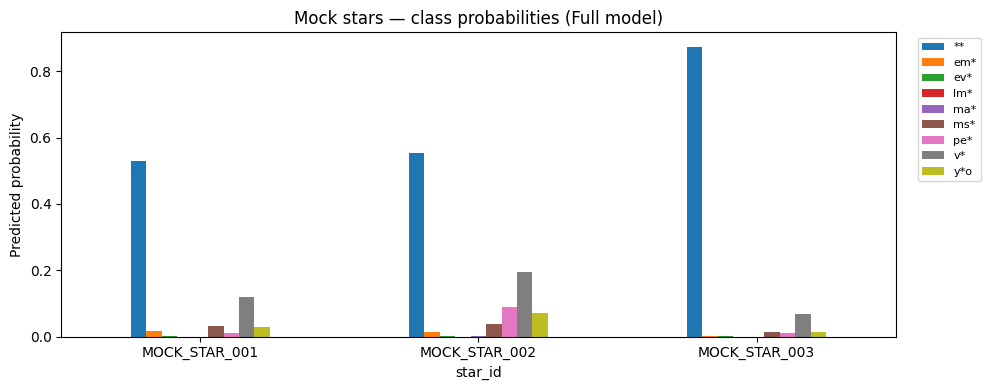

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
prob_cols = [c for c in scores.columns if c.startswith("prob_")]
plot_df = scores.set_index("star_id")[prob_cols]
plot_df.columns = [c.replace("prob_", "") for c in plot_df.columns]
plot_df.plot(kind="bar", ax=ax, rot=0)
ax.set_ylabel("Predicted probability")
ax.set_title("Mock stars — class probabilities (Full model)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()

## CLI equivalent

```powershell
python infer.py train --package Full
python infer.py predict --input data/mock_predict.dat --output data/mock_predict_scores.csv
```